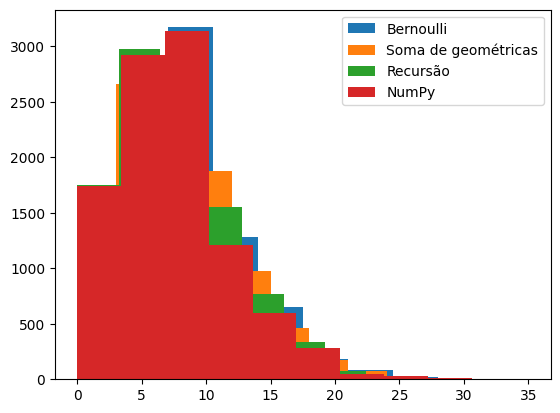

Tempo Bernoulli: 0.3200819492340088
Tempo soma de geométricas: 0.17244982719421387
Tempo recursão: 0.04750680923461914


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import time

K = 10000
r = 5
p = 0.4

amostra_bernoulli = []
inicio = time.time()

for i in range(K):
    sucessos = 0
    falhas = 0

    while sucessos < r:
        U = np.random.uniform()
        if U < p:
            sucessos += 1
        else:
            falhas += 1

    amostra_bernoulli.append(falhas)

tempo_bernoulli = time.time() - inicio

amostra_geometrica = []
inicio = time.time()

for i in range(K):
    falhas = 0

    for j in range(r):
        U = np.random.uniform()
        falhas += int(np.floor(np.log(1 - U) / np.log(1 - p)))

    amostra_geometrica.append(falhas)

tempo_geometrica = time.time() - inicio

amostra_recursao = []
inicio = time.time()

for i in range(K):
    U = np.random.uniform()
    probabilidade = p**r
    acumulada = probabilidade
    k = 0

    while U > acumulada:
        probabilidade = probabilidade * ((k + r) / (k + 1)) * (1 - p)
        acumulada += probabilidade
        k += 1

    amostra_recursao.append(k)

tempo_recursao = time.time() - inicio

amostra_numpy = np.random.negative_binomial(r, p, K)

plt.hist(amostra_bernoulli, label="Bernoulli")
plt.hist(amostra_geometrica, label="Soma de geométricas")
plt.hist(amostra_recursao, label="Recursão")
plt.hist(amostra_numpy, label="NumPy")
plt.legend()
plt.show()

print("Tempo Bernoulli:", tempo_bernoulli)
print("Tempo soma de geométricas:", tempo_geometrica)
print("Tempo recursão:", tempo_recursao)

(array([   6.,   51.,  311., 1086., 2158., 2735., 2198., 1126.,  295.,
          34.]),
 array([ 1. ,  1.9,  2.8,  3.7,  4.6,  5.5,  6.4,  7.3,  8.2,  9.1, 10. ]),
 <BarContainer object of 10 artists>)

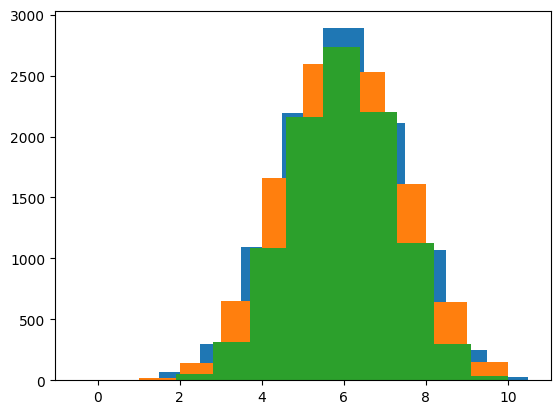

In [7]:
K = 10000
M = 20
N = 30
n = 10

amostra_fisher_yates = []
amostra_fisher_yates_errado = []

for repeticao in range(K):
    lista = [0] * M + [1] * N

    for i in range(n):
        j = np.random.randint(i, M + N)
        lista[i], lista[j] = lista[j], lista[i]

    amostra_fisher_yates.append(sum(lista[:n]))

for repeticao in range(K):
    lista = [0] * M + [1] * N

    for i in range(n):
        j = np.random.randint(0, M + N)
        lista[i], lista[j] = lista[j], lista[i]

    amostra_fisher_yates_errado.append(sum(lista[:n]))

amostra_numpy = np.random.hypergeometric(N, M, n, K)

plt.hist(amostra_fisher_yates, bins=bins, label="Fisher iates certo")
plt.hist(amostra_fisher_yates_errado, label="Fisher iates errado")
plt.hist(amostra_numpy, label="NumPy")

M + N = 100
Diferença entre as distribuições: 0.024859999999999976
M + N = 1000
Diferença entre as distribuições: 0.006969999999999988
M + N = 10000
Diferença entre as distribuições: 0.005800000000000022
M + N = 100000
Diferença entre as distribuições: 0.0034000000000000054
M + N = 1000000
Diferença entre as distribuições: 0.006400000000000035
M + N = 10000000
Diferença entre as distribuições: 0.0013999999999999993


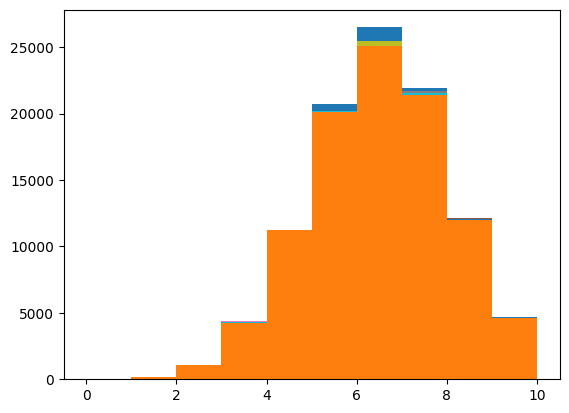

In [13]:
K = 100000
n = 10
valores_M = [40, 400, 4000, 40000, 400000, 4000000]

for M in valores_M:
    N = 1.5 * M
    N = int(N)
    p = N / (M + N)

    amostra_hipergeometrica = np.random.hypergeometric(N, M, n, K)
    amostra_binomial = np.random.binomial(n, p, K)

    plt.hist(amostra_hipergeometrica, label="Hipergeométrica")
    plt.hist(amostra_binomial, label="Binomial")
    
    frequencias_hipergeometrica = np.bincount(
        amostra_hipergeometrica, minlength=n + 1
    ) / K
    frequencias_binomial = np.bincount(
        amostra_binomial, minlength=n + 1
    ) / K

    diferenca = np.sum(
        np.abs(frequencias_hipergeometrica - frequencias_binomial)
    ) / 2

    print("M + N =", M + N)
    print("Diferença entre as distribuições:", diferenca)